# 08 | Unsichere Eingaben und ein fester Termin

Drei Arbeitsschritte werden nacheinander ausgeführt. Wie oft endet das
Projekt spätestens nach 10 Arbeitstagen? Das Beispiel übernimmt die
Dauertupel aus dem bisherigen Kapitel 1, nicht dessen fest notierte Ausgabe.

**Lernziele:** Eingabeannahmen begründen, eine Terminchance schätzen,
Modellunsicherheit von Monte-Carlo-Unsicherheit unterscheiden.
**Vorwissen:** Schleifen, Funktionen, Quote, SE und Intervall aus 04-07.
**Zeit:** geführte Demo, danach zwei Aufgaben mit je 15 Minuten.
Kursumgebung mit NumPy, Matplotlib, SciPy und statsmodels; keine Downloads.
Alle Basiszellen sind vollständig. Eigene Antworten in neue Zellen schreiben.

In [1]:
from random import Random
import math
from statistics import mean

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import beta, triang
from statsmodels.stats.proportion import proportion_confint

plt.rcParams.update({"font.size": 13})

## 1. Zuerst ohne Zufall

Backend 3 Tage, Integrationstest 2 Tage, Rollout 4 Tage: In Serie sind das
9 Tage. Beim Rollout wird erst nach dem Integrationstest begonnen.
Der optionale Funktionszweig `parallel=True` wird erst im Wahlteil gebraucht.

In [2]:
def gesamtdauer(dauern, parallel=False):
    if len(dauern) != 3 or not all(math.isfinite(wert) and wert >= 0 for wert in dauern):
        raise ValueError("Drei endliche nichtnegative Dauern erforderlich")
    if parallel:
        return max(dauern[0], dauern[1]) + dauern[2]
    return sum(dauern)


print("Serie:", gesamtdauer([3, 2, 4]))

Serie: 9


## 2. Ein Modellsteckbrief vor dem ersten Zufallslauf

| Schritt | Minimum | Modalwert | Maximum | Einheit / Begründung |
|---|---:|---:|---:|---|
| Backend | 2 | 3 | 6 | Arbeitstage; vorgegebene Lehrannahme |
| Integrationstest | 1 | 2 | 4 | Arbeitstage; vorgegebene Lehrannahme |
| Rollout | 3 | 4 | 9 | Arbeitstage; vorgegebene Lehrannahme |

Der Modalwert ist die Stelle der größten Dichte, nicht automatisch der
Mittelwert. Bei einer stetigen Verteilung hat ein einzelner exakter Wert
Wahrscheinlichkeit null. Minimum und Maximum sind harte Modellgrenzen,
nicht bloß kleinstes und größtes bisher beobachtetes Datum.

**Regeln:** Serie, unabhängige Dauern, keine Ausfälle oder Nacharbeit,
alle Ressourcen bei Bedarf verfügbar, keine Wochenenden oder Feiertage.
**Frage:** Anteil mit Gesamtzeit <= 10 Arbeitstage ab Projektstart.
**Datenstatus:** erfundene Unterrichtsparameter, keine Unternehmensmessung.
Im eigenen Projekt muss jede Angabe eine Quelle oder begründete Annahme haben.

In [3]:
arbeitsschritte = [("Backend", 2, 3, 6), ("Integrationstest", 1, 2, 4), ("Rollout", 3, 4, 9)]


def pruefe_dauerparameter(minimum, modalwert, maximum):
    if not all(math.isfinite(wert) for wert in [minimum, modalwert, maximum]):
        raise ValueError("Parameter muessen endlich sein")
    if not 0 <= minimum <= modalwert <= maximum:
        raise ValueError("Erforderlich: 0 <= Minimum <= Modalwert <= Maximum")


def ziehe_dauer(minimum, modalwert, maximum, generator, modell="dreieck"):
    pruefe_dauerparameter(minimum, modalwert, maximum)
    if modell not in {"dreieck", "pert"}:
        raise ValueError("Modell muss dreieck oder pert sein")
    if minimum == maximum:
        return float(minimum)
    if modell == "dreieck":
        return generator.triangular(low=minimum, high=maximum, mode=modalwert)
    form_links = 1 + 4 * (modalwert - minimum) / (maximum - minimum)
    form_rechts = 1 + 4 * (maximum - modalwert) / (maximum - minimum)
    return minimum + (maximum - minimum) * generator.betavariate(form_links, form_rechts)


generator = Random(42)
print("Eine Backenddauer:", ziehe_dauer(2, 3, 6, generator))

Eine Backenddauer: 3.9198849987307445


`Random.triangular` ist eine vorhandene Bibliotheksfunktion. Ihre benannten
Argumente verhindern, dass Modalwert und Maximum verwechselt werden.
Der PERT-Zweig ist erst im Wahlteil relevant; der Standard ist Dreieck.
Dreieck und PERT sind begründungsbedürftige Entscheidungen. Drei Angaben
bestimmen nicht automatisch eine Verteilung und keine eindeutige
Maximalentropie-Lösung dieser Art.

In [4]:
def projektdauern(arbeitsschritte, anzahl, seed, modell="dreieck", parallel=False):
    if len(arbeitsschritte) != 3 or anzahl <= 0:
        raise ValueError("Drei Arbeitsschritte und positive Laufzahl erforderlich")
    generator = Random(seed)
    ergebnisse = []
    for lauf in range(anzahl):
        dauern = []
        for name, minimum, modalwert, maximum in arbeitsschritte:
            dauern.append(ziehe_dauer(minimum, modalwert, maximum, generator, modell))
        ergebnisse.append(gesamtdauer(dauern, parallel=parallel))
    return ergebnisse


def terminbericht(dauern, frist):
    if not dauern or not math.isfinite(frist):
        raise ValueError("Nichtleere Dauerliste und endliche Frist erforderlich")
    if not all(math.isfinite(wert) and wert >= 0 for wert in dauern):
        raise ValueError("Endliche nichtnegative Dauern erforderlich")
    puenktlich = sum(dauer <= frist for dauer in dauern)
    unten, oben = proportion_confint(puenktlich, len(dauern), alpha=0.05, method="wilson")
    return {
        "laeufe": len(dauern),
        "mittelwert": mean(dauern),
        "quote": puenktlich / len(dauern),
        "quote_unten": float(unten),
        "quote_oben": float(oben),
        "p90": float(np.quantile(dauern, 0.9, method="inverted_cdf")),
    }


dauern = projektdauern(arbeitsschritte, 2000, 42)
print("Dreiecksmodell:", terminbericht(dauern, 10))

Dreiecksmodell: {'laeufe': 2000, 'mittelwert': 11.32960334445922, 'quote': 0.23, 'quote_unten': 0.21208456215584898, 'quote_oben': 0.24895064337602757, 'p90': 13.520491926898684}


Jeder Listeneintrag ist jetzt die Dauer eines vollständigen Projekts.
Die Quote hat einen Wilson-Bereich für ihre Monte-Carlo-Unsicherheit
bei festem Eingabemodell. Sie prüft nicht, ob die Eingabeannahmen richtig sind.
P90 ist hier das empirische 90%-Quantil: Mindestens 90% der simulierten
Projekte dauern höchstens so lange. Es ist kein Konfidenzintervall.
Die Interpolationskonvention `inverted_cdf` wählt einen beobachteten Wert.

**Ausgabe lesen:** `quote`, `quote_unten` und `quote_oben` sind Anteile
zwischen 0 und 1; mal 100 ergibt Prozent. `mittelwert` und `p90` sind dagegen
Dauern in Arbeitstagen. Für P90 sortieren wir die 2000 Dauern und lesen
den Wert an Platz 1800 (Python-Index 1799) ab. Das liefert eine Zeitgrenze
für simulierte Projekte, keine Garantie für ein neues reales Projekt.

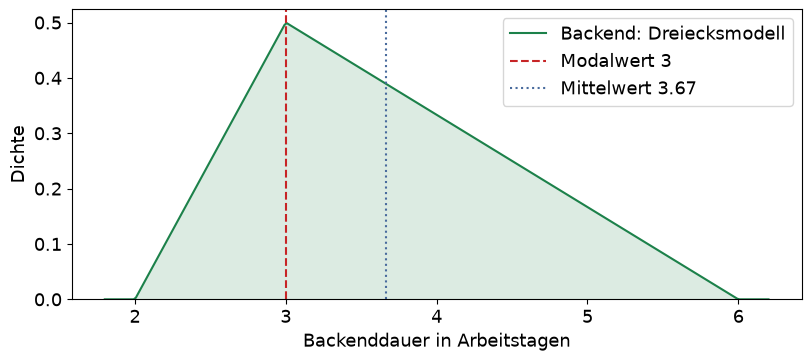

In [5]:
stellen = np.linspace(1.8, 6.2, 300)
dichte = triang.pdf(stellen, c=(3 - 2) / (6 - 2), loc=2, scale=6 - 2)
figur, achse = plt.subplots(figsize=(8, 3.5), layout="constrained")
achse.plot(stellen, dichte, color="#1c814a", label="Backend: Dreiecksmodell")
achse.fill_between(stellen, dichte, color="#dcebe2")
achse.axvline(3, color="#c72426", linestyle="--", label="Modalwert 3")
achse.axvline((2 + 3 + 6) / 3, color="#496b9d", linestyle=":", label="Mittelwert 3.67")
achse.set(xlabel="Backenddauer in Arbeitstagen", ylabel="Dichte", xticks=[2, 3, 4, 5, 6], ylim=(0, None))
achse.legend()
plt.show()
plt.close(figur)

Die Höhe einer Dichte ist keine Einzelwahrscheinlichkeit. Wahrscheinlichkeit
entspricht einer Fläche unter der Kurve. Die hohe Spitze bei 3 bedeutet
nicht, dass alle oder im Mittel genau 3 Tage benötigt werden.

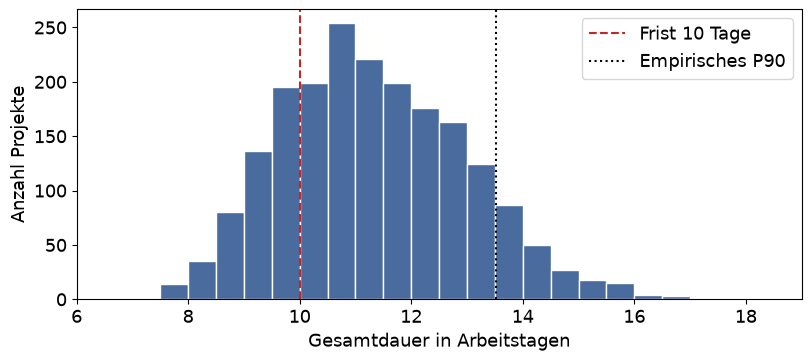

In [6]:
bericht = terminbericht(dauern, 10)
figur, achse = plt.subplots(figsize=(8, 3.5), layout="constrained")
achse.hist(dauern, bins=np.linspace(6, 19, 27), color="#496b9d", edgecolor="white")
achse.axvline(10, color="#c72426", linestyle="--", label="Frist 10 Tage")
achse.axvline(bericht["p90"], color="black", linestyle=":", label="Empirisches P90")
achse.set(xlabel="Gesamtdauer in Arbeitstagen", ylabel="Anzahl Projekte", xlim=(6, 19))
achse.legend()
plt.show()
plt.close(figur)

## Eigenarbeit | 30 Minuten

**A08.1 | 15 Minuten:** Benennen Sie den Quellenstatus der Eingaben und
eine denkbare Verletzung je Regel. Fehlende Datenbelege bleiben als solche
benannt; erfinden Sie keine Begründung für die Lehrparameter. Berechnen Sie die feste
Serie 3 + 2 + 4. Warum folgt daraus keine garantierte Einhaltung der Frist 10?
Benennen Sie Quote, deren Wilson-Intervall und P90 in der Notebookausgabe.

**A08.2 | 15 Minuten:** Ändern Sie nur das Backendmaximum von 6 auf 9 Tage.
Lassen Sie Minimum 2, Modalwert 3, Frist 10, Anzahl 2000 und Seed 42 gleich.
Vergleichen Sie Terminchance und P90. Formulieren Sie, welche Annahme Sie
verändert haben und welche Unsicherheit der Wilson-Bereich nicht abdeckt.
**Hilfe:** Erstellen Sie eine neue Liste mit dem ersten Tupel
`("Backend", 2, 3, 9)` und den beiden unveränderten Folgetupeln.
Speichern Sie `projektdauern(neue_schritte, 2000, 42)` als `neue_dauern`;
`terminbericht(neue_dauern, 10)` wertet genau diese Daten aus.
Die ursprünglichen Listen bleiben für den Vergleich unverändert.
Gleiche Seeds machen diesen Vergleich gepaart, nicht unabhängig.

## Drei Dinge bleiben

1. Eine Verteilung braucht eine fachliche Begründung, nicht nur drei Zahlen.
2. Serie addiert, Parallelität verlangt ein anderes Abhängigkeitsmodell.
3. Monte-Carlo-Unsicherheit wird mit mehr Läufen kleiner; falsche Eingaben
   werden dadurch nicht richtig. P90 und ein Intervall der Quote sind verschieden.

**Abschlussfrage:** Was bedeutet ein enges Intervall bei schlecht begründeten
Maximaldauern? Nur hohe Rechengenauigkeit innerhalb eines fraglichen Modells.
**Nächster Termin:** Quantile und Unsicherheit einer aus Daten geschätzten Kennzahl.
Hier endet der Pflichtteil.
CR08.1 (Quotenrechnung) und CR08.2 (Parallelregel) sind freiwillige
Moodle-Vertiefungen außerhalb der 30 Minuten Eigenarbeit.

## Wahlteil: PERT/Beta mit Gewicht 4

Wir verwenden eine skalierte Beta-Verteilung mit Formen
alpha = 1 + 4*(m-a)/(b-a), beta = 1 + 4*(b-m)/(b-a).
Der Faktor 4 ist eine Modellkonvention. Die Bibliotheksfunktion
`betavariate` liefert Beta-Werte, die wir auf [a,b] skalieren.
Dreieck hat Mittelwert (a+m+b)/3, dieses PERT-Modell (a+4*m+b)/6.
Der Vergleich verändert also im Allgemeinen auch den Mittelwert, nicht
nur die Streuung. Beide bleiben begründungsbedürftig.

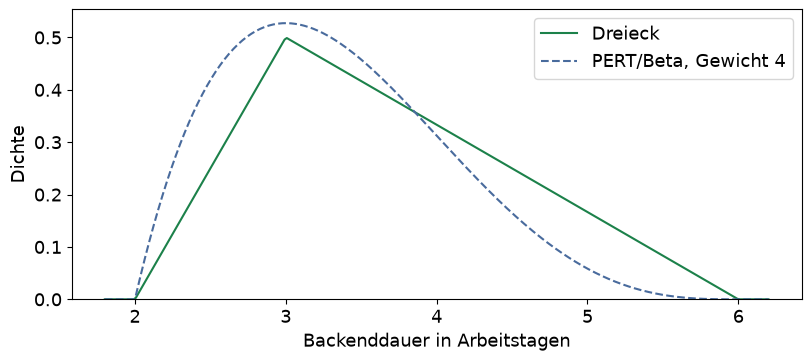

PERT/Beta: {'laeufe': 2000, 'mittelwert': 10.17539146973234, 'quote': 0.464, 'quote_unten': 0.44223367331256824, 'quote_oben': 0.48590435409168187, 'p90': 11.882260582098938}


In [7]:
form_links = 1 + 4 * (3 - 2) / (6 - 2)
form_rechts = 1 + 4 * (6 - 3) / (6 - 2)
figur, achse = plt.subplots(figsize=(8, 3.5), layout="constrained")
achse.plot(stellen, dichte, color="#1c814a", label="Dreieck")
achse.plot(stellen, beta.pdf(stellen, form_links, form_rechts, loc=2, scale=4),
           color="#496b9d", linestyle="--", label="PERT/Beta, Gewicht 4")
achse.set(xlabel="Backenddauer in Arbeitstagen", ylabel="Dichte", ylim=(0, None))
achse.legend()
plt.show()
plt.close(figur)
pert_dauern = projektdauern(arbeitsschritte, 2000, 42, modell="pert")
print("PERT/Beta:", terminbericht(pert_dauern, 10))

## Wahlteil: Parallelität und gemeinsam langsame Schritte

Ein hypothetisches Parallelmodell könnte die ersten zwei Schritte zeitgleich
starten und den dritten erst nach beiden. Dann gilt max(T1,T2)+T3.
Für Backend und dessen Integrationstest ist das meist nicht zulässig;
die Rechnung ist kein Vorschlag, diese Abhängigkeit zu ignorieren.
Zusätzliche Ressourcen und Voraussetzungen müssen geprüft werden.

Ein anderes Thema ist statistische Abhängigkeit: Ein Projekt kann in allen
Schritten gemeinsam langsam sein. Die folgende extreme Variante verwendet
pro Projekt dasselbe Quantil für alle drei Dreiecksverteilungen. Ihre
einzelnen Randverteilungen bleiben erhalten, aber die Dauern sind maximal
gleichgerichtet nach Rang. Das ist ein Sensitivitätsszenario, keine Schätzung
realer Abhängigkeit. Es gibt weiterhin keine Überschreitung der einzelnen Maxima.

In [8]:
def gekoppelte_projektdauern(arbeitsschritte, anzahl, seed):
    if len(arbeitsschritte) != 3 or anzahl <= 0:
        raise ValueError("Drei Arbeitsschritte und positive Laufzahl erforderlich")
    generator = Random(seed)
    ergebnisse = []
    for lauf in range(anzahl):
        quantilniveau = generator.random()
        zeit = 0.0
        for name, minimum, modalwert, maximum in arbeitsschritte:
            pruefe_dauerparameter(minimum, modalwert, maximum)
            if minimum == maximum:
                zeit += minimum
            else:
                breite = maximum - minimum
                zeit += float(triang.ppf(quantilniveau, c=(modalwert - minimum) / breite,
                                        loc=minimum, scale=breite))
        ergebnisse.append(zeit)
    return ergebnisse


print("Hypothetisch erste zwei parallel:",
      terminbericht(projektdauern(arbeitsschritte, 2000, 42, parallel=True), 10))
print("Gleichgerichtet gekoppelte Serie:",
      terminbericht(gekoppelte_projektdauern(arbeitsschritte, 2000, 42), 10))

Hypothetisch erste zwei parallel: {'laeufe': 2000, 'mittelwert': 9.052035326923658, 'quote': 0.7355, 'quote_unten': 0.7157315552920355, 'quote_oben': 0.7543655154384944, 'p90': 11.091001952569695}
Gleichgerichtet gekoppelte Serie: {'laeufe': 2000, 'mittelwert': 11.382248206624046, 'quote': 0.3665, 'quote_unten': 0.34565708171038617, 'quote_oben': 0.3878547699137082, 'p90': 15.35890765851061}


Mehr Abhängigkeit bedeutet nicht für jede Frist automatisch eine kleinere
Terminchance: Die Form der Gesamtdauerverteilung ändert sich. Vergleichen
Sie Terminchance und P90 getrennt. Eine allgemeine Projekt-Netzplanung mit
vielen Ressourcen und Kalendern wird hier nicht vorgetäuscht.